# TC3-43 – Analisar distribuição do target

**Responsável:** Mauricio Cruz

**Sprint:** Fase 3

**Jira:** TC3-43

## Objetivo

Avaliar a distribuição da variável-alvo alfabetizado, identificando as classes existentes, calculando suas quantidades absolutas e proporções percentuais, verificando a presença de desbalanceamento e representando os resultados por meio de gráfico. Documentar as conclusões e os possíveis impactos na escolha das métricas e na avaliação dos modelos de Machine Learning.


In [16]:
import polars as pl
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

### Carregamento dos dados (partitioned by sigla_uf)

In [17]:
# Ajuste o caminho conforme a localização real no seu ambiente

# Localiza a raiz do projeto a partir do diretório atual do notebook.
# Assim o notebook funciona no VS Code, Jupyter local ou outro clone do repositório.
def encontrar_raiz_projeto():
    atual = Path.cwd().resolve()
    for candidato in [atual, *atual.parents]:
        if (candidato / "dados" / "principal" / "ml_aluno.zip").exists():
            return candidato
    raise FileNotFoundError(
        "Não foi possível encontrar dados/principal/ml_aluno.zip. "
        "Execute o notebook dentro do repositório ou confira se os dados foram baixados."
    )

PROJECT_ROOT = encontrar_raiz_projeto()

BASE_PATH = PROJECT_ROOT / "dados" / "consolidado" / "base_alunos_municipios_por_uf"
# Leitura lazy (muito mais eficiente com partições)
df = pl.scan_parquet(
    f"{BASE_PATH}/sigla_uf=*/00000000.parquet",
    hive_partitioning=True
)

### Avaliação da distribuição da variável-alvo alfabetizado

In [18]:
# Contagem absoluta e proporção
distribuicao = (
    df
    .select("alfabetizado")
    .collect()                          # materializa só a coluna necessária
    .group_by("alfabetizado")
    .agg(pl.len().alias("quantidade"))
    .with_columns(
        (pl.col("quantidade") / pl.col("quantidade").sum() * 100)
        .round(2)
        .alias("proporcao_pct")
    )
    .sort("quantidade", descending=True)
)

print("=== Distribuição da variável-alvo 'alfabetizado' ===")
print(distribuicao)

=== Distribuição da variável-alvo 'alfabetizado' ===
shape: (2, 3)
┌──────────────┬────────────┬───────────────┐
│ alfabetizado ┆ quantidade ┆ proporcao_pct │
│ ---          ┆ ---        ┆ ---           │
│ i32          ┆ u64        ┆ f64           │
╞══════════════╪════════════╪═══════════════╡
│ 1            ┆ 1984546    ┆ 51.31         │
│ 0            ┆ 1883453    ┆ 48.69         │
└──────────────┴────────────┴───────────────┘


### Visualização

C:\Users\Mauripi\AppData\Local\Temp\ipykernel_1740\2207956226.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


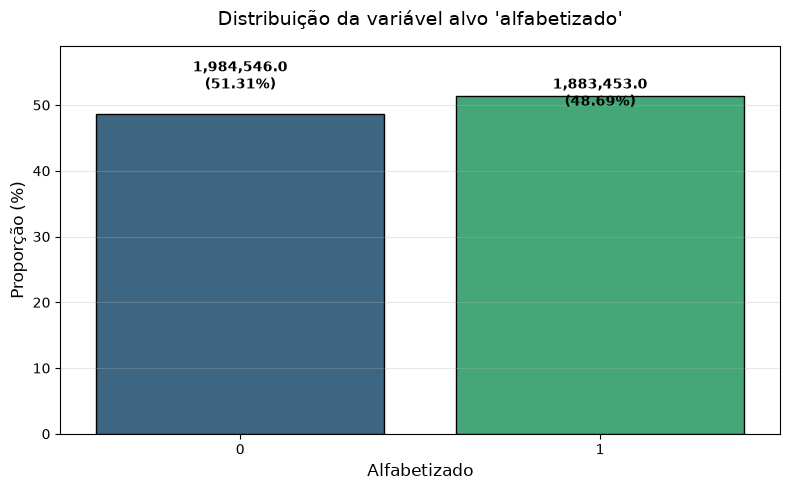

In [20]:
# Prepara dados para o gráfico
df_plot = distribuicao.to_pandas()

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=df_plot,
    x="alfabetizado",
    y="proporcao_pct",
    palette="viridis",
    edgecolor="black"
)

# Adiciona valores absolutos e percentuais nas barras
for i, row in df_plot.iterrows():
    ax.text(
        i,
        row["proporcao_pct"] + 0.5,
        f'{row["quantidade"]:,}\n({row["proporcao_pct"]}%)',
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

plt.title("Distribuição da variável alvo 'alfabetizado'", fontsize=14, pad=15)
plt.xlabel("Alfabetizado", fontsize=12)
plt.ylabel("Proporção (%)", fontsize=12)
plt.ylim(0, df_plot["proporcao_pct"].max() * 1.15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Diagnóstico de desbalanceamento

In [22]:
# Razão entre a classe majoritária e a minoritária
qtd = distribuicao["quantidade"].to_list()
labels = distribuicao["alfabetizado"].to_list()

majoritaria = max(qtd)
minoritaria = min(qtd)
razao = majoritaria / minoritaria if minoritaria > 0 else float("inf")

print("\n=== Diagnóstico de Desbalanceamento ===")
print(f"Classe majoritária : {labels[qtd.index(majoritaria)]} → {majoritaria:,} ({distribuicao.filter(pl.col('quantidade') == majoritaria)['proporcao_pct'][0]}%)")
print(f"Classe minoritária : {labels[qtd.index(minoritaria)]} → {minoritaria:,} ({distribuicao.filter(pl.col('quantidade') == minoritaria)['proporcao_pct'][0]}%)")
print(f"Razão de desbalanceamento: {razao:.2f}:1")


=== Diagnóstico de Desbalanceamento ===
Classe majoritária : 1 → 1,984,546 (51.31%)
Classe minoritária : 0 → 1,883,453 (48.69%)
Razão de desbalanceamento: 1.05:1


### Verificar missing values no target

In [24]:
nulls_target = (
    df
    .select(
        pl.col("alfabetizado").null_count().alias("nulos"),
        pl.len().alias("total")
    )
    .with_columns(
        (pl.col("nulos") / pl.col("total") * 100).round(4).alias("pct_nulos")
    )
    .collect()
)

print(nulls_target)

shape: (1, 3)
┌───────┬─────────┬───────────┐
│ nulos ┆ total   ┆ pct_nulos │
│ ---   ┆ ---     ┆ ---       │
│ u64   ┆ u64     ┆ f64       │
╞═══════╪═════════╪═══════════╡
│ 0     ┆ 3867999 ┆ 0.0       │
└───────┴─────────┴───────────┘


### Distribuição do target por UF

In [25]:
dist_por_uf = (
    df
    .group_by("sigla_uf", "alfabetizado")
    .agg(pl.len().alias("qtd"))
    .with_columns(
        (pl.col("qtd") / pl.col("qtd").sum().over("sigla_uf") * 100)
        .round(2)
        .alias("pct")
    )
    .sort("sigla_uf", "alfabetizado")
    .collect()
)

print(dist_por_uf)

# Pivot para ficar mais legível
dist_pivot = (
    dist_por_uf
    .pivot(index="sigla_uf", on="alfabetizado", values="pct")
    .sort("sigla_uf")
)
print(dist_pivot)

shape: (52, 4)
┌──────────┬──────────────┬────────┬───────┐
│ sigla_uf ┆ alfabetizado ┆ qtd    ┆ pct   │
│ ---      ┆ ---          ┆ ---    ┆ ---   │
│ str      ┆ i32          ┆ u64    ┆ f64   │
╞══════════╪══════════════╪════════╪═══════╡
│ AC       ┆ 0            ┆ 7344   ┆ 58.03 │
│ AC       ┆ 1            ┆ 5311   ┆ 41.97 │
│ AL       ┆ 0            ┆ 39133  ┆ 56.57 │
│ AL       ┆ 1            ┆ 30038  ┆ 43.43 │
│ AM       ┆ 0            ┆ 72843  ┆ 59.87 │
│ …        ┆ …            ┆ …      ┆ …     │
│ SE       ┆ 1            ┆ 12697  ┆ 33.36 │
│ SP       ┆ 0            ┆ 212195 ┆ 47.82 │
│ SP       ┆ 1            ┆ 231582 ┆ 52.18 │
│ TO       ┆ 0            ┆ 24024  ┆ 60.34 │
│ TO       ┆ 1            ┆ 15793  ┆ 39.66 │
└──────────┴──────────────┴────────┴───────┘
shape: (26, 3)
┌──────────┬───────┬───────┐
│ sigla_uf ┆ 0     ┆ 1     │
│ ---      ┆ ---   ┆ ---   │
│ str      ┆ f64   ┆ f64   │
╞══════════╪═══════╪═══════╡
│ AC       ┆ 58.03 ┆ 41.97 │
│ AL       ┆ 56.57 ┆ 43.43 │
│ 

### Verifica se existe alguma UF muito desbalanceada

In [26]:
# Diferença absoluta entre as classes por UF
desbal_uf = (
    dist_por_uf
    .pivot(index="sigla_uf", on="alfabetizado", values="pct")
    .with_columns(
        (pl.col("1") - pl.col("0")).abs().alias("diff_abs")
    )
    .sort("diff_abs", descending=True)
)

print(desbal_uf)

shape: (26, 4)
┌──────────┬───────┬───────┬──────────┐
│ sigla_uf ┆ 0     ┆ 1     ┆ diff_abs │
│ ---      ┆ ---   ┆ ---   ┆ ---      │
│ str      ┆ f64   ┆ f64   ┆ f64      │
╞══════════╪═══════╪═══════╪══════════╡
│ CE       ┆ 17.89 ┆ 82.11 ┆ 64.22    │
│ RN       ┆ 69.58 ┆ 30.42 ┆ 39.16    │
│ BA       ┆ 68.06 ┆ 31.94 ┆ 36.12    │
│ SE       ┆ 66.64 ┆ 33.36 ┆ 33.28    │
│ ES       ┆ 37.43 ┆ 62.57 ┆ 25.14    │
│ …        ┆ …     ┆ …     ┆ …        │
│ MA       ┆ 47.36 ┆ 52.64 ┆ 5.28     │
│ DF       ┆ 52.56 ┆ 47.44 ┆ 5.12     │
│ PB       ┆ 52.39 ┆ 47.61 ┆ 4.78     │
│ SP       ┆ 47.82 ┆ 52.18 ┆ 4.36     │
│ MT       ┆ 48.82 ┆ 51.18 ┆ 2.36     │
└──────────┴───────┴───────┴──────────┘


### Desbalanceamento por UF (gráfico)

C:\Users\Mauripi\AppData\Local\Temp\ipykernel_1740\2483510969.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


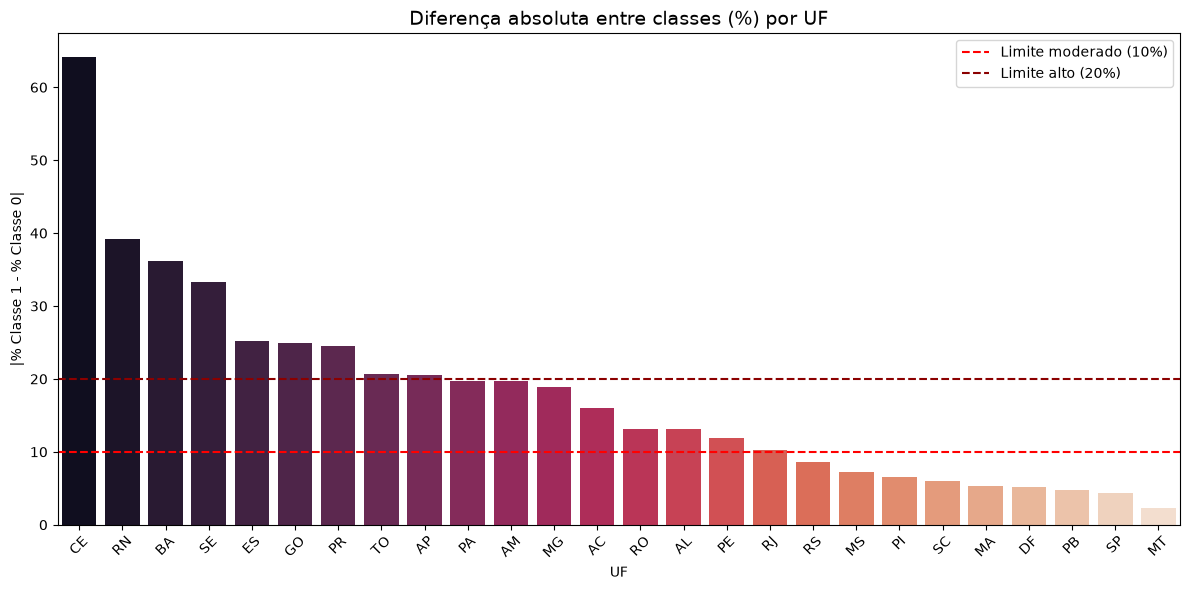

In [27]:

desbal_plot = desbal_uf.sort("diff_abs", descending=True)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=desbal_plot.to_pandas(),
    x="sigla_uf",
    y="diff_abs",
    palette="rocket"
)
plt.axhline(10, color="red", linestyle="--", label="Limite moderado (10%)")
plt.axhline(20, color="darkred", linestyle="--", label="Limite alto (20%)")
plt.title("Diferença absoluta entre classes (%) por UF", fontsize=14)
plt.xlabel("UF")
plt.ylabel("|% Classe 1 - % Classe 0|")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

### Volume de alunos por UF

Para ver se os estados desbalanceados têm peso grande

In [28]:
volume_uf = (
    df
    .group_by("sigla_uf")
    .agg(pl.len().alias("total_alunos"))
    .with_columns(
        (pl.col("total_alunos") / pl.col("total_alunos").sum() * 100).round(2).alias("pct_total")
    )
    .sort("total_alunos", descending=True)
    .collect()
)

print(volume_uf)

shape: (26, 3)
┌──────────┬──────────────┬───────────┐
│ sigla_uf ┆ total_alunos ┆ pct_total │
│ ---      ┆ ---          ┆ ---       │
│ str      ┆ u64          ┆ f64       │
╞══════════╪══════════════╪═══════════╡
│ SP       ┆ 443777       ┆ 11.47     │
│ MG       ┆ 413557       ┆ 10.69     │
│ RJ       ┆ 311198       ┆ 8.05      │
│ PR       ┆ 277446       ┆ 7.17      │
│ BA       ┆ 253300       ┆ 6.55      │
│ …        ┆ …            ┆ …         │
│ TO       ┆ 39817        ┆ 1.03      │
│ SE       ┆ 38058        ┆ 0.98      │
│ DF       ┆ 27698        ┆ 0.72      │
│ AP       ┆ 24929        ┆ 0.64      │
│ AC       ┆ 12655        ┆ 0.33      │
└──────────┴──────────────┴───────────┘


### Análise de heterogeneidade geográfica do target

- O target está globalmente balanceado (51,3% vs 48,7%).
- Entretanto, existe forte variação entre UFs:
  - Ceará apresenta o maior desbalanceamento (≈64 pontos percentuais a favor da classe 1).
  - Rio Grande do Norte, Bahia e Sergipe também mostram desbalanceamento relevante (>30 pp).
  - São Paulo, Minas Gerais e Mato Grosso estão entre os mais equilibrados.

- Estados com maior volume de alunos (SP, MG, RJ) tendem a ser mais balanceados.
- Estados do Nordeste concentram os maiores desbalanceamentos.

Implicações para modelagem:
- Necessário avaliar performance por UF.
- Recomenda-se validação estratificada ou GroupKFold por sigla_uf.
- Possível necessidade de modelos regionais ou features que capturem contexto geográfico.